In [34]:
#próbka po plazmie tlenowo-argonowej 0 i 2 s
from funkcje.Lorentz2Raman import *

In [35]:
#import wszystkich mapek dla próbki 4
BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka4" / "dane_pomiarowe"

rs_PL_0s, I_PL_0s = importMap(sciezka/"WSe2_mapa_PL_4_0s.txt")
rs_PL_2s, I_PL_2s = importMap(sciezka/"WSe2_mapa_PL_4_2s.txt")


rs_Raman_0s, I_Raman_0s = importMap(sciezka/"WSe2_mapa_Raman_4_0s.txt")
rs_Raman_2s, I_Raman_2s = importMap(sciezka/"WSe2_mapa_Raman_4_2s.txt")

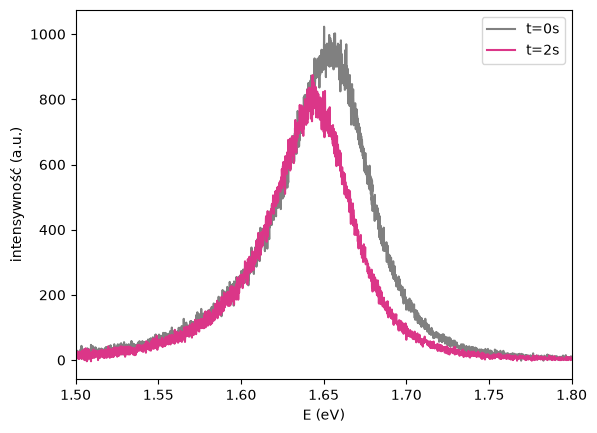

In [36]:
#testowe pojedyncze widma PL, żebym wiedziała co dopasować 
plt.plot(rs_PL_0s[123], I_PL_0s[123],label="t=0s",color='gray')
plt.plot(rs_PL_2s[123], I_PL_2s[110],label="t=2s",color="#DB3688")
plt.xlabel(r"E (eV)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(1.5,1.8)
BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka4" / "wykresy"
plt.savefig(sciezka/'PL_2s.png')

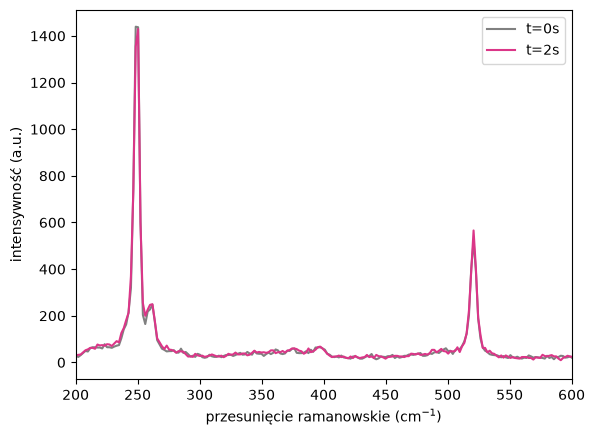

In [37]:
# testowe pojedyncze widma ramana, żebym wiedziała co dopasować 
plt.plot(rs_Raman_0s[123], I_Raman_0s[123],label="t=0s",color='gray')
plt.plot(rs_Raman_2s[123], I_Raman_2s[123],label="t=2s",color="#DB3688")
plt.xlabel(r"przesunięcie ramanowskie (cm$^{-1}$)")
plt.ylabel("intensywność (a.u.)")
plt.legend()
plt.xlim(200,600)
plt.savefig(sciezka/'Raman_2s.png')

In [38]:
#dopasowanie piku PL

centers_PL_0s, fwhms_PL_0s, intensities_PL_0s = lorentz2map(rs_PL_0s, I_PL_0s, xmin=1.5, xmax=1.7)
centers_PL_2s, fwhms_PL_2s, intensities_PL_2s = lorentz2map(rs_PL_2s, I_PL_2s, xmin=1.55, xmax=1.75)

(array([144.,  31.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   1.]),
 array([0.04866362, 0.06055092, 0.07243821, 0.0843255 , 0.09621279,
        0.10810008, 0.11998738, 0.13187467, 0.14376196, 0.15564925,
        0.16753654]),
 <BarContainer object of 10 artists>)

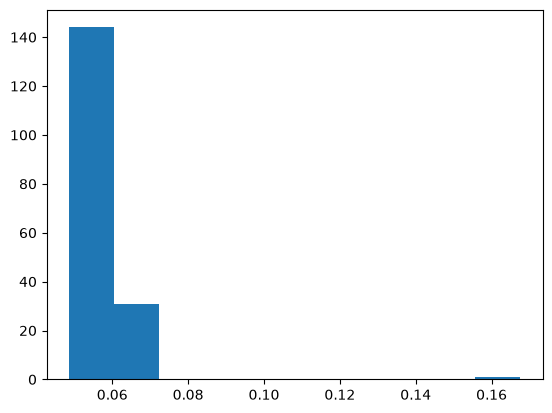

In [39]:
plt.hist(fwhms_PL_2s)

In [40]:
#usunięcie punktów mocno odstających - krawędzi monowarswty/samego podłoża = dla widm ramaniowskich niepewnosc fwhm w granicach warstosci
maska_PL_0s=(fwhms_PL_0s>=0) &(fwhms_PL_0s<=0.08)
fwhms_PL_0s=fwhms_PL_0s[maska_PL_0s]
centers_PL_0s=centers_PL_0s[maska_PL_0s]
intensities_PL_0s=intensities_PL_0s[maska_PL_0s]

maska_PL_2s=(fwhms_PL_2s>=0) &(fwhms_PL_2s<=0.08)
fwhms_PL_2s=fwhms_PL_2s[maska_PL_2s]
centers_PL_2s=centers_PL_2s[maska_PL_2s]
intensities_PL_2s=intensities_PL_2s[maska_PL_2s]


In [41]:
#dopasowanie piku E i A

centers_Raman_EA_0s, fwhms_Raman_EA_0s, intensities_Raman_EA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=240, xmax=255)
centers_Raman_EA_2s, fwhms_Raman_EA_2s, intensities_Raman_EA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=240, xmax=255)

In [42]:
#usunięcie punktów mocno odstających - krawędzi monowarswty/samego podłoża = dla widm ramaniowskich niepewnosc fwhm w granicach warstosci
maska_Raman_EA_0s=(fwhms_Raman_EA_0s>=0) &(fwhms_Raman_EA_0s<=16)
fwhms_Raman_EA_0s=fwhms_Raman_EA_0s[maska_Raman_EA_0s]
centers_Raman_EA_0s=centers_Raman_EA_0s[maska_Raman_EA_0s]
intensities_Raman_EA_0s=intensities_Raman_EA_0s[maska_Raman_EA_0s]

maska_Raman_EA_2s=(fwhms_Raman_EA_2s>=0) &(fwhms_Raman_EA_2s<=20)
fwhms_Raman_EA_2s=fwhms_Raman_EA_2s[maska_Raman_EA_2s]
centers_Raman_EA_2s=centers_Raman_EA_2s[maska_Raman_EA_2s]
intensities_Raman_EA_2s=intensities_Raman_EA_2s[maska_Raman_EA_2s]


In [43]:
#dopasowanie piku 2LA(M)

centers_Raman_LA_0s, fwhms_Raman_LA_0s, intensities_Raman_LA_0s = lorentz2map(rs_Raman_0s, I_Raman_0s, xmin=255, xmax=265)
centers_Raman_LA_2s, fwhms_Raman_LA_2s, intensities_Raman_LA_2s = lorentz2map(rs_Raman_2s, I_Raman_2s, xmin=255, xmax=265)


In [44]:
maska_Raman_LA_0s=(fwhms_Raman_LA_0s>=0) &(fwhms_Raman_LA_0s<=25)
fwhms_Raman_LA_0s=fwhms_Raman_LA_0s[maska_Raman_LA_0s]
centers_Raman_LA_0s=centers_Raman_LA_0s[maska_Raman_LA_0s]
intensities_Raman_LA_0s=intensities_Raman_LA_0s[maska_Raman_LA_0s]

maska_Raman_LA_2s=(fwhms_Raman_LA_2s>=0) &(fwhms_Raman_LA_2s<=25)
fwhms_Raman_LA_2s=fwhms_Raman_LA_2s[maska_Raman_LA_2s]
centers_Raman_LA_2s=centers_Raman_LA_2s[maska_Raman_LA_2s]
intensities_Raman_LA_2s=intensities_Raman_LA_2s[maska_Raman_LA_2s]

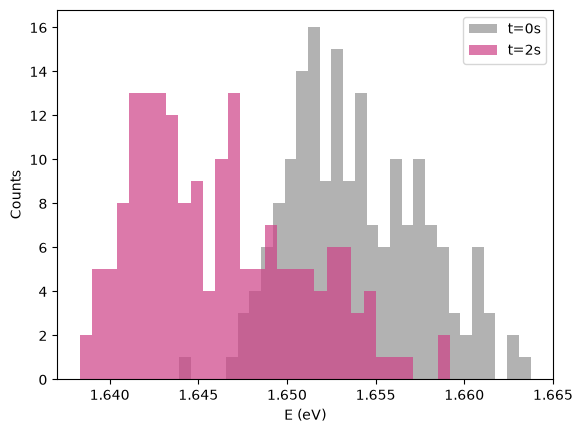

In [45]:
#histogramy pozycji piku PL

plt.hist(centers_PL_0s, bins=30, label="t=0s",alpha=0.6,color='gray')
plt.hist(centers_PL_2s, bins=30, label="t=2s",alpha=0.70,color="#CE4087")

plt.xlabel(r"E (eV)")
plt.ylabel("Counts")
plt.legend()


BASE = Path().resolve()
sciezka = BASE / "analiza" / "próbka4" / "wykresy"
plt.savefig(sciezka/'histogram_pozycji_PL.png')

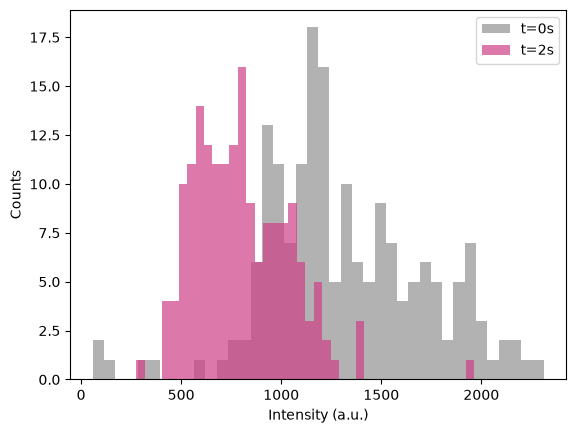

In [ ]:
#histogramy intensywności piku PL
plt.hist(intensities_PL_0s, bins=40, label="t=0s",alpha=0.6,color='gray')
plt.hist(intensities_PL_2s, bins=40, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"Intensity (a.u.)")
plt.ylabel("Counts")
plt.legend()

plt.savefig(sciezka/'histogram_intensywnosci_PL.png')

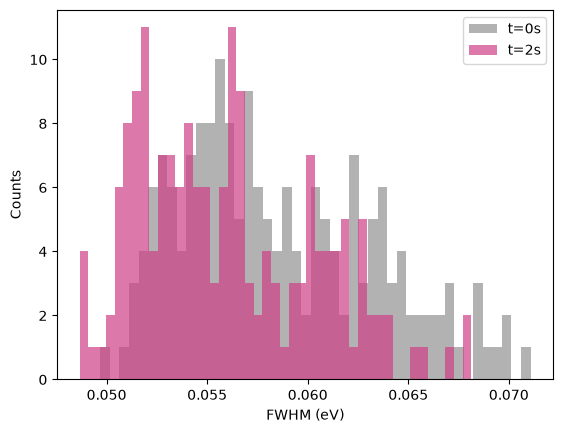

In [47]:
#histogramy fwhm piku PL

plt.hist(fwhms_PL_0s, bins=45, label="t=0s", alpha=0.6,color='gray')
plt.hist(fwhms_PL_2s, bins=45, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"FWHM (eV)")
plt.ylabel("Counts")
plt.legend()

plt.savefig(sciezka/'histogram_fwhm_PL.png')

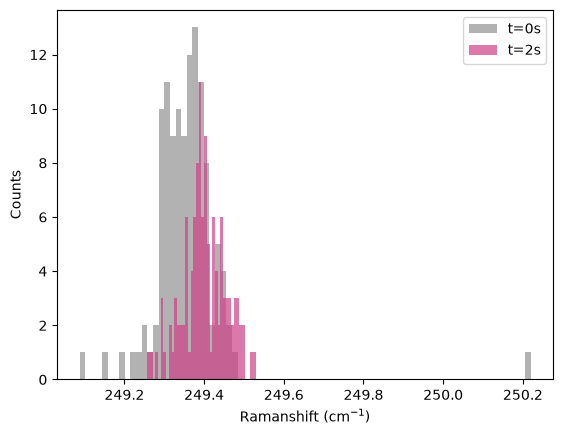

In [48]:
#histogramy pozycji piku Raman E i A

plt.hist(centers_Raman_EA_0s, bins=80, label="t=0s", alpha=0.6,color='gray')
plt.hist(centers_Raman_EA_2s, bins=40, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"Ramanshift (cm$^{-1}$)")
plt.ylabel("Counts")
plt.legend()

plt.savefig(sciezka/'histogram_pozycji_Raman_EA.png')

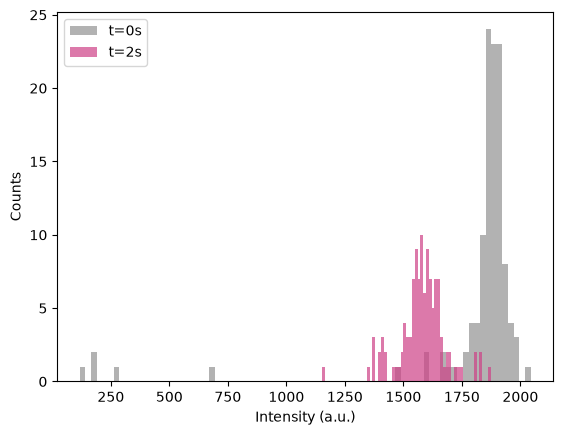

In [49]:
#histogramy intensywności Raman E i A

plt.hist(intensities_Raman_EA_0s, bins=80, label="t=0s", alpha=0.6,color='gray')
plt.hist(intensities_Raman_EA_2s, bins=60, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"Intensity (a.u.)")
plt.ylabel("Counts")
plt.legend()
plt.savefig(sciezka/'histogram_intensywnosci_Raman_EA.png')

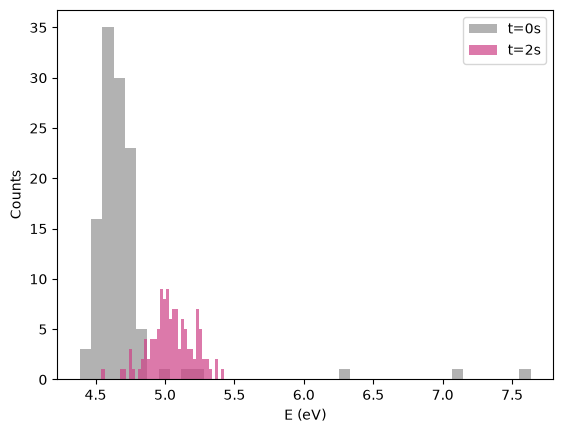

In [50]:
#histogramy fwhm piku Raman E i A

plt.hist(fwhms_Raman_EA_0s, bins=40, label="t=0s", alpha=0.6,color='gray')
plt.hist(fwhms_Raman_EA_2s, bins=40, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"E (eV)")
plt.ylabel("Counts")
plt.legend()
plt.savefig(sciezka/'histogram_fwhm_Raman_EA.png')

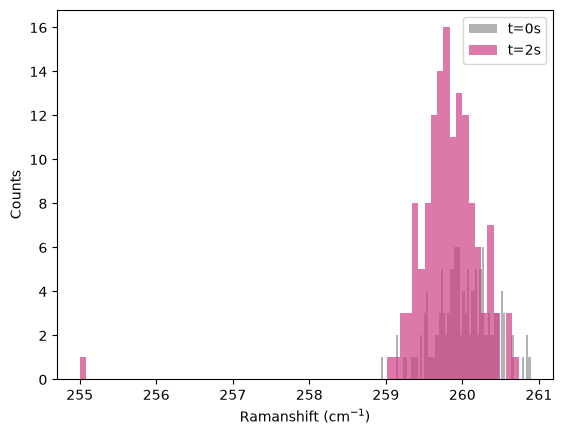

In [51]:
#histogramy pozycji piku Raman 2LA(M)

plt.hist(centers_Raman_LA_0s, bins=70, label="t=0s", alpha=0.6,color='gray')
plt.hist(centers_Raman_LA_2s, bins=70, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"Ramanshift (cm$^{-1}$)")
plt.ylabel("Counts")
plt.legend()

plt.savefig(sciezka/'histogram_pozycji_Raman_LA.png')

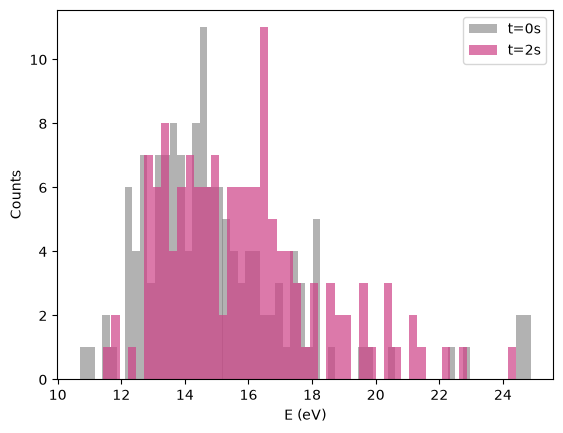

In [52]:
#histogramy fwhm piku Raman 2LA(M)

plt.hist(fwhms_Raman_LA_0s, bins=60, label="t=0s", alpha=0.6,color='gray')
plt.hist(fwhms_Raman_LA_2s, bins=50, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"E (eV)")
plt.ylabel("Counts")
plt.legend()
plt.savefig(sciezka/'histogram_fwhm_Raman_LA.png')

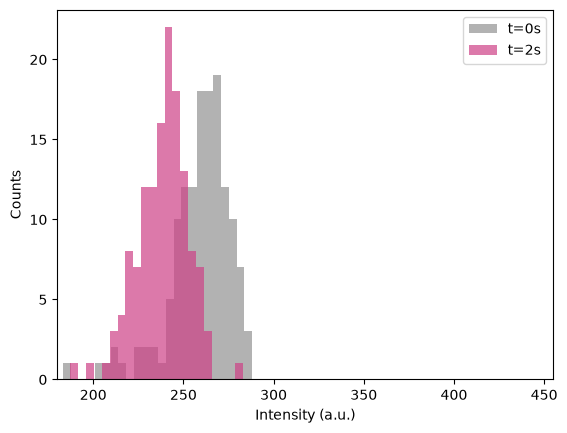

In [53]:
#histogramy intensywności Raman 2LA(M)

plt.hist(intensities_Raman_LA_0s, bins=60, label="t=0s", alpha=0.6,color='gray')
plt.hist(intensities_Raman_LA_2s, bins=45, label="t=2s",alpha=0.70,color="#CE4087")
plt.xlabel(r"Intensity (a.u.)")
plt.ylabel("Counts")
plt.legend()
plt.xlim(180,455)
plt.savefig(sciezka/'histogram_intensywnosci_Raman_LA.png')

In [54]:
mu_centers_PL_0s, sigma_centers_PL_0s = norm.fit(centers_PL_0s)
print(f"{mu_centers_PL_0s} ± {sigma_centers_PL_0s}")
x_centers_PL_0s,y_centers_PL_0s=gauss(mu_centers_PL_0s,sigma_centers_PL_0s)

mu_centers_PL_2s, sigma_centers_PL_2s = norm.fit(centers_PL_2s)
print(f"{mu_centers_PL_2s} ± {sigma_centers_PL_2s}")
x_centers_PL_2s,y_centers_PL_2s=gauss(mu_centers_PL_2s,sigma_centers_PL_2s)

1.6538966432356865 ± 0.00372529168966509
1.6461278378367699 ± 0.004615397941618796


In [55]:
mu_intensities_PL_0s, sigma_intensities_PL_0s = norm.fit(intensities_PL_0s)
print(f"{mu_intensities_PL_0s} ± {sigma_intensities_PL_0s}")
x_intensities_PL_0s,y_intensities_PL_0s=gauss(mu_intensities_PL_0s,sigma_intensities_PL_0s)


mu_intensities_PL_2s, sigma_intensities_PL_2s = norm.fit(intensities_PL_2s)
print(f"{mu_intensities_PL_2s} ± {sigma_intensities_PL_2s}")
x_intensities_PL_2s,y_intensities_PL_2s=gauss(mu_intensities_PL_2s,sigma_intensities_PL_2s)

1309.2536265421372 ± 407.63460035833043
798.3975244494328 ± 238.97653871330755


In [56]:
mu_fwhms_PL_0s, sigma_fwhms_PL_0s = norm.fit(fwhms_PL_0s)
print(f"{mu_fwhms_PL_0s} ± {sigma_fwhms_PL_0s}")
x_fwhms_PL_0s,y_fwhms_PL_0s=gauss(mu_fwhms_PL_0s,sigma_fwhms_PL_0s)


mu_fwhms_PL_2s, sigma_fwhms_PL_2s = norm.fit(fwhms_PL_2s)
print(f"{mu_fwhms_PL_2s} ± {sigma_fwhms_PL_2s}")
x_fwhms_PL_2s,y_fwhms_PL_2s=gauss(mu_fwhms_PL_2s,sigma_fwhms_PL_2s)

0.058550009766765596 ± 0.0048400622064151974
0.05599819832834342 ± 0.004342487266478595


In [57]:
mu_centers_Raman_EA_0s, sigma_centers_Raman_EA_0s = norm.fit(centers_Raman_EA_0s)
print(f"{mu_centers_Raman_EA_0s} ± {sigma_centers_Raman_EA_0s}")
x_centers_Raman_EA_0s,y_centers_Raman_EA_0s=gauss(mu_centers_Raman_EA_0s,sigma_centers_Raman_EA_0s)

mu_centers_Raman_EA_2s, sigma_centers_Raman_EA_2s = norm.fit(centers_Raman_EA_2s)
print(f"{mu_centers_Raman_EA_2s} ± {sigma_centers_Raman_EA_2s}")
x_centers_Raman_EA_2s,y_centers_Raman_EA_2s=gauss(mu_centers_Raman_EA_2s,sigma_centers_Raman_EA_2s)

249.357248840049 ± 0.10011633410646446
249.40059747397893 ± 0.054400489964116706


In [58]:
mu_intensities_Raman_EA_0s, sigma_intensities_Raman_EA_0s = norm.fit(intensities_Raman_EA_0s)
print(f"{mu_intensities_Raman_EA_0s} ± {sigma_intensities_Raman_EA_0s}")
x_intensities_Raman_EA_0s,y_intensities_Raman_EA_0s=gauss(mu_intensities_Raman_EA_0s,sigma_intensities_Raman_EA_0s)

mu_intensities_Raman_EA_2s, sigma_intensities_Raman_EA_2s = norm.fit(intensities_Raman_EA_2s)
print(f"{mu_intensities_Raman_EA_2s} ± {sigma_intensities_Raman_EA_2s}")
x_intensities_Raman_EA_2s,y_intensities_Raman_EA_2s=gauss(mu_intensities_Raman_EA_2s,sigma_intensities_Raman_EA_2s)

1801.4664446291067 ± 331.4352501429438
1579.449909889076 ± 102.26594410072907


In [59]:
mu_fwhms_Raman_EA_0s, sigma_fwhms_Raman_EA_0s = norm.fit(fwhms_Raman_EA_0s)
print(f"{mu_fwhms_Raman_EA_0s} ± {sigma_fwhms_Raman_EA_0s}")
x_fwhms_Raman_EA_0s,y_fwhms_Raman_EA_0s=gauss(mu_fwhms_Raman_EA_0s,sigma_fwhms_Raman_EA_0s)

mu_fwhms_Raman_EA_2s, sigma_fwhms_Raman_EA_2s = norm.fit(fwhms_Raman_EA_2s)
print(f"{mu_fwhms_Raman_EA_2s} ± {sigma_fwhms_Raman_EA_2s}")
x_fwhms_Raman_EA_2s,y_fwhms_Raman_EA_2s=gauss(mu_fwhms_Raman_EA_2s,sigma_fwhms_Raman_EA_2s)

4.709036064148761 ± 0.40141116253758774
5.048869650557617 ± 0.1549992863186404


In [60]:
mu_centers_Raman_LA_0s, sigma_centers_Raman_LA_0s = norm.fit(centers_Raman_LA_0s)
print(f"{mu_centers_Raman_LA_0s} ± {sigma_centers_Raman_LA_0s}")
x_centers_Raman_LA_0s,y_centers_Raman_LA_0s=gauss(mu_centers_Raman_LA_0s,sigma_centers_Raman_LA_0s)

mu_centers_Raman_LA_2s, sigma_centers_Raman_LA_2s = norm.fit(centers_Raman_LA_2s)
print(f"{mu_centers_Raman_LA_2s} ± {sigma_centers_Raman_LA_2s}")
x_centers_Raman_LA_2s,y_centers_Raman_LA_2s=gauss(mu_centers_Raman_LA_2s,sigma_centers_Raman_LA_2s)

260.0090284856632 ± 0.36403169770566146
259.81370133743906 ± 0.5269213967065274


In [61]:
mu_intensities_Raman_LA_0s, sigma_intensities_Raman_LA_0s = norm.fit(intensities_Raman_LA_0s)
print(f"{mu_intensities_Raman_LA_0s} ± {sigma_intensities_Raman_LA_0s}")
x_intensities_Raman_LA_0s,y_intensities_Raman_LA_0s=gauss(mu_intensities_Raman_LA_0s,sigma_intensities_Raman_LA_0s)

mu_intensities_Raman_LA_2s, sigma_intensities_Raman_LA_2s = norm.fit(intensities_Raman_LA_2s)
print(f"{mu_intensities_Raman_LA_2s} ± {sigma_intensities_Raman_LA_2s}")
x_intensities_Raman_LA_2s,y_intensities_Raman_LA_2s=gauss(mu_intensities_Raman_LA_2s,sigma_intensities_Raman_LA_2s)

257.622914672658 ± 26.025065471544806
236.62553601932004 ± 21.263359202527184


In [62]:
mu_fwhms_Raman_LA_0s, sigma_fwhms_Raman_LA_0s = norm.fit(fwhms_Raman_LA_0s)
print(f"{mu_fwhms_Raman_LA_0s} ± {sigma_fwhms_Raman_LA_0s}")
x_fwhms_Raman_LA_0s,y_fwhms_Raman_LA_0s=gauss(mu_fwhms_Raman_LA_0s,sigma_fwhms_Raman_LA_0s)

mu_fwhms_Raman_LA_2s, sigma_fwhms_Raman_LA_2s = norm.fit(fwhms_Raman_LA_2s)
print(f"{mu_fwhms_Raman_LA_2s} ± {sigma_fwhms_Raman_LA_2s}")
x_fwhms_Raman_LA_2s,y_fwhms_Raman_LA_2s=gauss(mu_fwhms_Raman_LA_2s,sigma_fwhms_Raman_LA_2s)

15.08913726286181 ± 2.644732815287055
15.8479706611594 ± 2.4256354056768554
